# Iris Generativa com NatGenAI — iteração 2.3

Este notebook compara **seis condições**: SBX, OB-Scan-KDE, híbrido probabilístico, mistura gaussiana, mistura com produtos gaussianos normalizados e VAE-EDA condicional. Cada execução Iris mantém 50 registros por espécie.

**Perfil padrão: `quick`**, destinado a verificar integração e execução. Seus resultados não sustentam uma comparação científica definitiva. Para o protocolo completo, altere `EXECUTION_PROFILE = "full"` em `iris_generativa/config.py` e reinicie o kernel antes de executar todas as células.

Referência: [Evolutionary Computation as Natural Generative AI](https://arxiv.org/html/2510.08590v1). SBX, OB-Scan baseado em KDE e o híbrido equiprovável são discutidos no artigo; a aplicação Iris, o fitness, as cotas KMeans e os protocolos discriminativos são adaptações deste projeto. Anel/espiral são reconstruções ilustrativas. Os cenários gaussianos usam as médias, covariâncias e pesos descritos no artigo, com estimação empírica das distribuições parentais.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import SVG, display

ROOT = Path.cwd() if (Path.cwd() / "iris_generativa").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from iris_generativa import config
from iris_generativa.data import load_iris_data, prepare_context, build_calibration_table
from iris_generativa.generative import run_condition
from iris_generativa.extended_experiments import (
    execution_settings, run_metadata, run_suite, robustness_suite,
    crossfit_suite, iris_selection_ablation, sensitivity_suite, condition_options,
)
from iris_generativa.evaluation import (
    summarize_generation, build_distribution_table, evaluate_discriminators,
)
from iris_generativa.benchmarks import run_benchmarks, plot_benchmarks, selection_study
from iris_generativa.progress import progress

settings = execution_settings()
metadata = run_metadata(settings)
print(json.dumps(metadata, ensure_ascii=False, indent=2))

{
  "python": "3.14.7",
  "versions": {
    "numpy": "2.5.3",
    "pandas": "3.0.6",
    "scikit-learn": "1.9.1",
    "pygad": "3.7.0",
    "torch": "2.14.1",
    "tqdm": "4.70.1"
  },
  "settings": {
    "profile": "full",
    "generations": 40,
    "vae_epochs": 30,
    "benchmark_size": 200,
    "benchmark_generations": 20,
    "seeds": [
      0,
      1,
      2,
      3,
      4,
      5,
      6,
      7,
      8,
      9,
      10,
      11,
      12,
      13,
      14,
      15,
      16,
      17,
      18,
      19
    ],
    "evaluation": {
      "n_splits": 5,
      "n_repeats": 5,
      "n_estimators": 300,
      "n_jobs": 1
    }
  },
  "configuration": {
    "SEED": 42,
    "CV_SEED": 2026,
    "POP_SIZE": 50,
    "GENERATIONS": 40,
    "RMP": 0.2,
    "TOURNAMENT_SIZE": 3,
    "SBX_ETA": 50.0,
    "POLY_ETA": 20.0,
    "POLY_MUTATION_PROB": 0.2,
    "INITIAL_JITTER": 0.08,
    "N_NICHES": 5,
    "K_NEIGHBORS": 5,
    "FITNESS_WEIGHTS": {
      "plausibility": 0.5,
   

## Pipeline atualizada

As rotas 2A e 2B são condições alternativas. Cada geração produz candidatos e aplica sobrevivência. Os parâmetros das distribuições e do VAE são ajustados novamente nos pais selecionados. O cross-fitting repete os blocos 1–4 com contexto e modelos novos para cada fold.

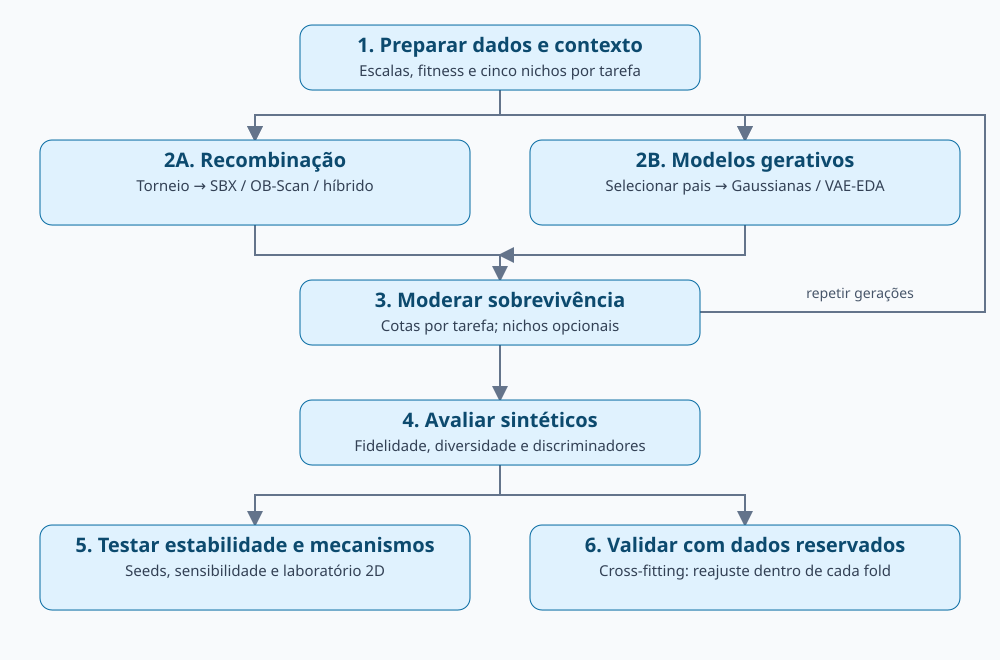

In [2]:
display(SVG(filename=str(ROOT / "docs" / "pipeline.svg")))

## 1. Contexto e fitness

O `StandardScaler` é ajustado somente nos dados disponíveis à execução. A inicialização amostra registros reais da tarefa e acrescenta ruído gaussiano com desvio 0,08 em unidades padronizadas. Não se trata de amostragem a partir de ruído puro.

O fitness é **0,50 plausibilidade + 0,25 novidade + 0,25 coerência**. Plausibilidade utiliza proximidade local; novidade favorece uma distância-alvo calibrada nos vizinhos reais, não aumenta indefinidamente com a distância; coerência mede compatibilidade relativa com a espécie. O KMeans mantém até cinco nichos fixos por tarefa.

In [3]:
data = load_iris_data()
x_real, species = data["x_real"], data["y_species"]
context = prepare_context(x_real, species, config.SEED)
display(build_calibration_table(context, data["species_names"]))

,novelty_target,novelty_sigma,plausibility_scale
species,,,
setosa,0.195439,0.110129,0.327372
versicolor,0.287635,0.098517,0.402340
virginica,0.344166,0.133930,0.478102


## 2. Gerar candidatos

| Condição | Como gera candidatos |
|---|---|
| SBX | Seleciona pais por torneio e executa crossover SBX. |
| OB-Scan | Usa KDE por gene no pool parental e amostra o crossover OB-Scan. |
| Híbrido 50/50 | Sorteia SBX ou OB-Scan para cada descendente; não impõe metade exata. |
| Mistura gaussiana | Ajusta uma gaussiana por tarefa nos melhores pais; peso 0,70 para a tarefa-alvo e 0,15 para cada outra tarefa. |
| Mistura + produto | Destina 0,60 às gaussianas individuais e 0,40 aos produtos normalizados por pares, divididos igualmente em cada grupo. Produto das três tarefas é opcional. |
| VAE-EDA | Ajusta VAE condicional nos melhores 50% de cada tarefa, amostra latentes e decodifica com o rótulo da tarefa. |

O VAE usa uma camada oculta de 64 unidades no encoder e decoder e latente de 32 dimensões. O objetivo soma reconstrução MSE e KL. Pesos e Adam podem continuar entre gerações da mesma execução; cada seed, condição e fold começa um modelo novo. Gaussianas são ajustadas a cada geração. Não é uma mistura aprendida por EM.

## 3. Sobrevivência moderada

Na Iris, `task` preserva cotas por espécie e `task_niching` acrescenta cotas de nichos. Nos novos métodos, a seleção parental para ajustar o modelo antecede essa seleção de sobreviventes. A política `global`, que pode eliminar tarefas, é restrita ao laboratório 2D. Os candidatos Iris são limitados à caixa definida no contexto; eventos dos novos modelos registram clipping, componente e sobrevivência.

In [4]:
conditions = list(config.MAIN_CONDITIONS)
if config.RUN_EXTENDED:
    conditions += list(config.GENERATIVE_METHODS)
runs = run_suite(context, conditions=conditions, settings=settings)
for name, result in runs.items():
    assert result["synthetic_x"].shape == (150, 4)
    assert np.isfinite(result["synthetic_x"]).all()
    assert np.array_equal(np.bincount(result["synthetic_species"]), [50, 50, 50])
display(pd.DataFrame([{ "condition": name, **result["history"].iloc[-1].to_dict()}
                      for name, result in runs.items()]))

Condições gerativas:   0%|          | 0/6 [00:00<?, ?it/s]

,condition,generation,fitness_evaluations,elapsed_seconds,fitness_mean,fitness_max,generated_sbx,generated_obscan,generated_model,survived_offspring,clipped
0,SBX,40.0,54000.0,6.452316,0.791452,0.925261,150.0,0.0,NaN,NaN,NaN
1,OB-Scan,40.0,54000.0,10.581407,0.782181,0.899851,0.0,150.0,NaN,NaN,NaN
2,Híbrido 50/50,40.0,54000.0,7.900466,0.788897,0.924035,79.0,71.0,NaN,NaN,NaN
3,gaussian_mixture,40.0,24000.0,2.149495,0.812680,0.923341,0.0,0.0,150.0,6.0,0.0
4,gaussian_product,40.0,24000.0,2.205331,0.800102,0.918281,0.0,0.0,150.0,3.0,14.0
5,vae_eda,40.0,24000.0,12.884145,0.746359,0.900255,0.0,0.0,150.0,1.0,0.0


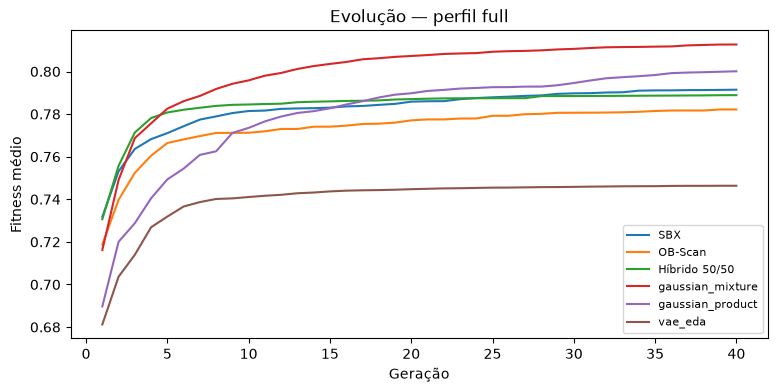

,generation,epoch,loss,reconstruction,kl
0,1,1,4.451061,3.682917,0.768144
1,1,2,4.089784,3.511406,0.578377
2,1,3,3.884418,3.442827,0.441591
3,1,4,3.654732,3.307361,0.347371
4,1,5,3.572993,3.287191,0.285802
...,...,...,...,...,...
1195,40,26,0.079284,0.079061,0.000223
1196,40,27,0.078615,0.078391,0.000224
1197,40,28,0.078769,0.078549,0.000220
1198,40,29,0.080661,0.080437,0.000224


,clipped,survived
generation,,
1,0,30
2,0,36
3,0,30
4,0,41
5,0,29
6,0,32
7,0,22
8,0,21
9,0,7


In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
for name, result in runs.items():
    ax.plot(result["history"]["generation"], result["history"]["fitness_mean"], label=name)
ax.set(xlabel="Geração", ylabel="Fitness médio", title=f"Evolução — perfil {settings['profile']}")
ax.legend(loc="best", fontsize=8)
plt.show()
if "vae_eda" in runs:
    display(runs["vae_eda"]["training_history"])
    display(runs["vae_eda"]["offspring_events"].groupby("generation")[["clipped", "survived"]].sum())

## 4. Avaliação dos sintéticos

Duplicação exata, coerência k-NN, distância ao real mais próximo, diversidade e fidelidade marginal complementam o teste real × sintético. Discriminadores: Regressão Logística e Random Forest, com estratificação conjunta de origem e espécie. A avaliação abaixo reutiliza reais que orientaram o gerador; o bloco 6 reserva reais fora desse ajuste. Baixa distinguibilidade não demonstra validade biológica nem criatividade fora da distribuição.

In [6]:
summary, real_diversity = summarize_generation(runs, context, x_real, species)
display(summary)
distributions = build_distribution_table(runs, x_real, species, data["feature_names"],
                                         data["species_names"], context["tasks"])
display(distributions.groupby("condition")[["wasserstein", "ks"]].mean())
discriminator_tables = {}
for name, result in progress(runs.items(), "Avaliar condições"):
    discriminator_tables[name] = evaluate_discriminators(
        x_real, species, result["synthetic_x"], result["synthetic_species"],
        **settings["evaluation"])
display(pd.concat(discriminator_tables, names=["condition", "model"]))

,duplicates,species_coherence,novelty_mean,diversity,diversity_ratio
condition,,,,,
SBX,0,0.993333,0.221062,2.331234,0.928802
OB-Scan,0,0.993333,0.222780,2.223419,0.885847
Híbrido 50/50,0,0.993333,0.226300,2.256791,0.899143
gaussian_mixture,0,0.993333,0.236869,2.360065,0.940289
gaussian_product,0,0.986667,0.228589,2.323178,0.925592
vae_eda,0,0.980000,0.216357,2.348250,0.935581


,wasserstein,ks
condition,,
Híbrido 50/50,0.127887,0.331667
OB-Scan,0.130102,0.378333
SBX,0.138847,0.386667
gaussian_mixture,0.140702,0.325000
gaussian_product,0.119050,0.281667
vae_eda,0.116660,0.313333


Avaliar condições:   0%|          | 0/6 [00:00<?, ?it/s]

accuracy_mean  precision_mean  \
condition        model                                                
SBX              Regressão Logística       0.530667        0.537223   
                 Random Forest             0.878667        0.847344   
OB-Scan          Regressão Logística       0.470000        0.468255   
                 Random Forest             0.912000        0.871552   
Híbrido 50/50    Regressão Logística       0.518000        0.527820   
                 Random Forest             0.906000        0.857888   
gaussian_mixture Regressão Logística       0.512667        0.512856   
                 Random Forest             0.840667        0.798353   
gaussian_product Regressão Logística       0.464000        0.464347   
                 Random Forest             0.838000        0.817378   
vae_eda          Regressão Logística       0.557333        0.577509   
                 Random Forest             0.777333        0.735883   

                                      recall_mean   f1_mean  roc_auc_mean  \
condition        model                                                      
SBX              Regressão Logística     0.486667  0.507185      0.522889   
                 Random Forest           0.929333  0.884692      0.940000   
OB-Scan          Regressão Logística     0.521333  0.490843      0.521511   
                 Random Forest           0.969333  0.917157      0.954000   
Híbrido 50/50    Regressão Logística     0.489333  0.501731      0.531511   
                 Random Forest           0.977333  0.912767      0.949333   
gaussian_mixture Regressão Logística     0.481333  0.492650      0.509422   
                 Random Forest           0.916000  0.852086      0.910889   
gaussian_product Regressão Logística     0.458667  0.459742      0.480000   
                 Random Forest           0.874667  0.843192      0.909511   
vae_eda          Regressão Logística     0.494667  0.526376      0.530711   
                 Random Forest           0.876000  0.797360      0.866244   

                                      accuracy_std  precision_std  recall_std  \
condition        model                                                          
SBX              Regressão Logística      0.074488       0.086527    0.096609   
                 Random Forest            0.029257       0.046339    0.048369   
OB-Scan          Regressão Logística      0.072419       0.068250    0.129230   
                 Random Forest            0.031098       0.042626    0.029695   
Híbrido 50/50    Regressão Logística      0.069429       0.080228    0.092722   
                 Random Forest            0.034603       0.046546    0.033625   
gaussian_mixture Regressão Logística      0.069006       0.082375    0.111188   
                 Random Forest            0.036842       0.043505    0.043328   
gaussian_product Regressão Logística      0.049369       0.049848    0.070098   
                 Random Forest            0.033506       0.041145    0.063442   
vae_eda          Regressão Logística      0.059643       0.092046    0.080928   
                 Random Forest            0.041333       0.050851    0.064992   

                                        f1_std  roc_auc_std  
condition        model                                       
SBX              Regressão Logística  0.080310     0.067628  
                 Random Forest        0.026738     0.028593  
OB-Scan          Regressão Logística  0.091136     0.071832  
                 Random Forest        0.028349     0.023286  
Híbrido 50/50    Regressão Logística  0.067791     0.063333  
                 Random Forest        0.030662     0.025283  
gaussian_mixture Regressão Logística  0.089407     0.070100  
                 Random Forest        0.032777     0.027284  
gaussian_product Regressão Logística  0.053616     0.043703  
                 Random Forest        0.033886     0.027577  
vae_eda          Regressão Logística  0.058968     0.057767  
                 Random

## 5. Robustez, sensibilidade e experimentos artificiais

O perfil completo executa 20 seeds pareadas; o rápido executa duas. A sensibilidade varia η do SBX e RMP, e a ablação compara sobrevivência por tarefa com e sem nichos. Mutação polinomial permanece em laboratório separado.

O laboratório 2D compara SBX (η=5/50), OB-Scan, híbrido e VAE condicional em anel/espiral e gaussianas anisotrópicas. No segundo cenário, acrescenta misturas 0,7/0,3 e 0,5/0,5 e mistura-produto 0,3/0,3/0,4. É uma demonstração de amostragem em uma geração, sem otimização pelo fitness Iris. SBX/OB-Scan têm limites derivados do pool parental; VAE/Gaussianas nesse laboratório não sofrem clipping. Portanto, a fração fora do casco convexo é descritiva e depende também desses mecanismos.

O estudo de seleção usa o fitness adaptado da Iris em duas dimensões: compara trajetórias e aplica as três políticas aos mesmos candidatos de cada trajetória (controle contrafactual). Ele não reproduz um MFEA completo.

In [7]:
if config.RUN_ROBUSTNESS:
    robustness = robustness_suite(context, x_real, species, conditions, settings)
    display(robustness.groupby("condition")[["rf_accuracy", "rf_roc_auc", "diversity_ratio"]].agg(["mean", "std"]))
if config.RUN_SENSITIVITY:
    display(sensitivity_suite(context, x_real, species, settings))
    display(iris_selection_ablation(context, x_real, species, settings))
if config.RUN_POLYNOMIAL_LAB:
    polynomial = run_condition(context, config.SEED, "SBX",
                               **condition_options("SBX", settings, use_polynomial_mutation=True))
    display(evaluate_discriminators(x_real, species, polynomial["synthetic_x"],
                                   polynomial["synthetic_species"], **settings["evaluation"]))

Robustez: execuções:   0%|          | 0/120 [00:00<?, ?it/s]

rf_accuracy           rf_roc_auc           diversity_ratio  \
                        mean       std       mean       std            mean   
condition                                                                     
Híbrido 50/50       0.875300  0.012766   0.938844  0.007264        0.932417   
OB-Scan             0.881267  0.018451   0.941919  0.010887        0.919918   
SBX                 0.860967  0.013803   0.937261  0.007381        0.940239   
gaussian_mixture    0.836100  0.021399   0.911009  0.016314        0.942189   
gaussian_product    0.826633  0.019313   0.903933  0.014249        0.937338   
vae_eda             0.756067  0.022153   0.853523  0.020848        0.961103   

                            
                       std  
condition                   
Híbrido 50/50     0.021372  
OB-Scan           0.018489  
SBX               0.016624  
gaussian_mixture  0.008406  
gaussian_product  0.011329  
vae_eda           0.010335

Sensibilidade:   0%|          | 0/5 [00:00<?, ?it/s]

,case,profile,rf_accuracy,rf_roc_auc
0,SBX eta=5,full,0.844667,0.910444
1,SBX eta=30,full,0.876667,0.935089
2,SBX eta=50,full,0.878667,0.940000
3,Híbrido RMP=0,full,0.894000,0.945133
4,Híbrido RMP=0.2,full,0.906000,0.949333


Ablação Iris: seleção:   0%|          | 0/2 [00:00<?, ?it/s]

,policy,profile,rf_accuracy,rf_roc_auc
0,task,full,1.000,1.000000
1,task_niching,full,0.906,0.949333


,accuracy_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean,accuracy_std,precision_std,recall_std,f1_std,roc_auc_std
model,,,,,,,,,,
Regressão Logística,0.486000,0.488500,0.440000,0.458844,0.475467,0.061043,0.07089,0.085375,0.068365,0.051647
Random Forest,0.883333,0.840597,0.949333,0.890607,0.935600,0.032318,0.03986,0.045333,0.030069,0.029582


Cenários 2D:   0%|          | 0/2 [00:00<?, ?it/s]

VAE: épocas:   0%|          | 0/30 [00:00<?, ?it/s]

VAE: épocas:   0%|          | 0/30 [00:00<?, ?it/s]

,scenario,method,seed,outside_parent_hull,mean_displacement,covariance_trace
0,geometry,SBX eta=5,42,0.2450,0.552713,0.521954
1,geometry,SBX eta=50,42,0.1525,0.542267,0.487854
2,geometry,OB-Scan,42,0.0050,0.150239,0.387551
3,geometry,Híbrido,42,0.0875,0.262908,0.555504
4,geometry,VAE condicional,42,0.0000,0.020131,0.163720
5,anisotropic,SBX eta=5,42,0.5000,2.342276,13.026364
6,anisotropic,SBX eta=50,42,0.4875,2.291408,12.512428
7,anisotropic,OB-Scan,42,0.4400,1.857843,14.863291
8,anisotropic,Híbrido,42,0.4675,2.069398,13.799470
9,anisotropic,VAE condicional,42,0.0025,0.052319,17.802817


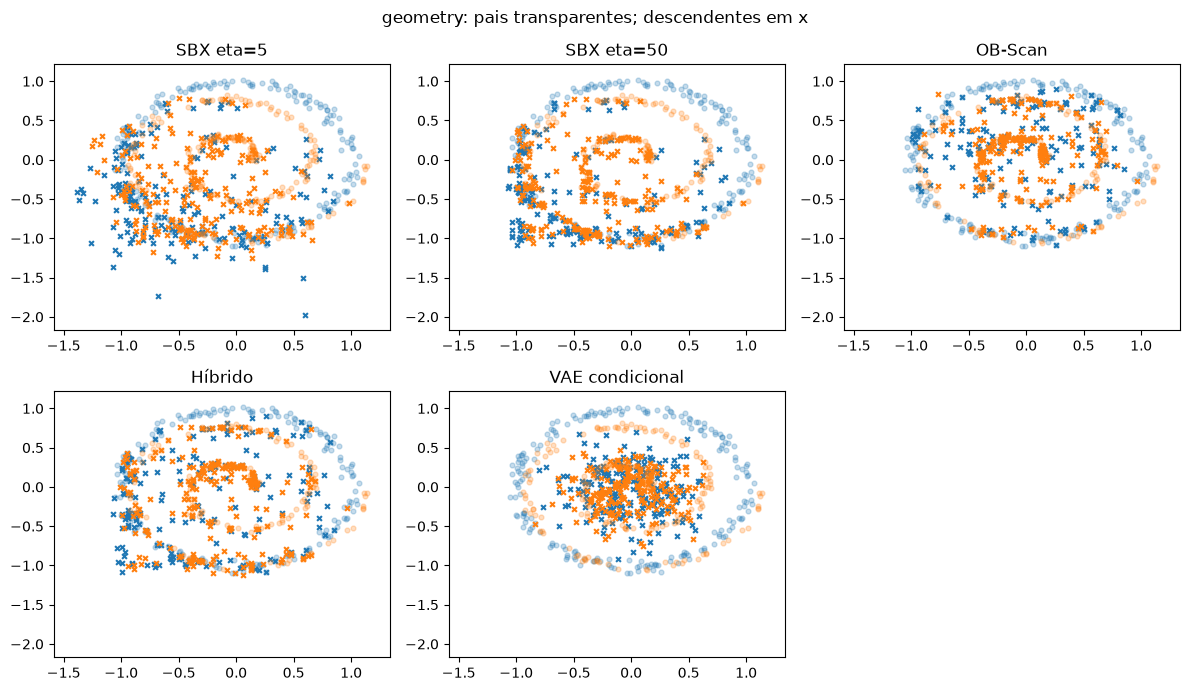

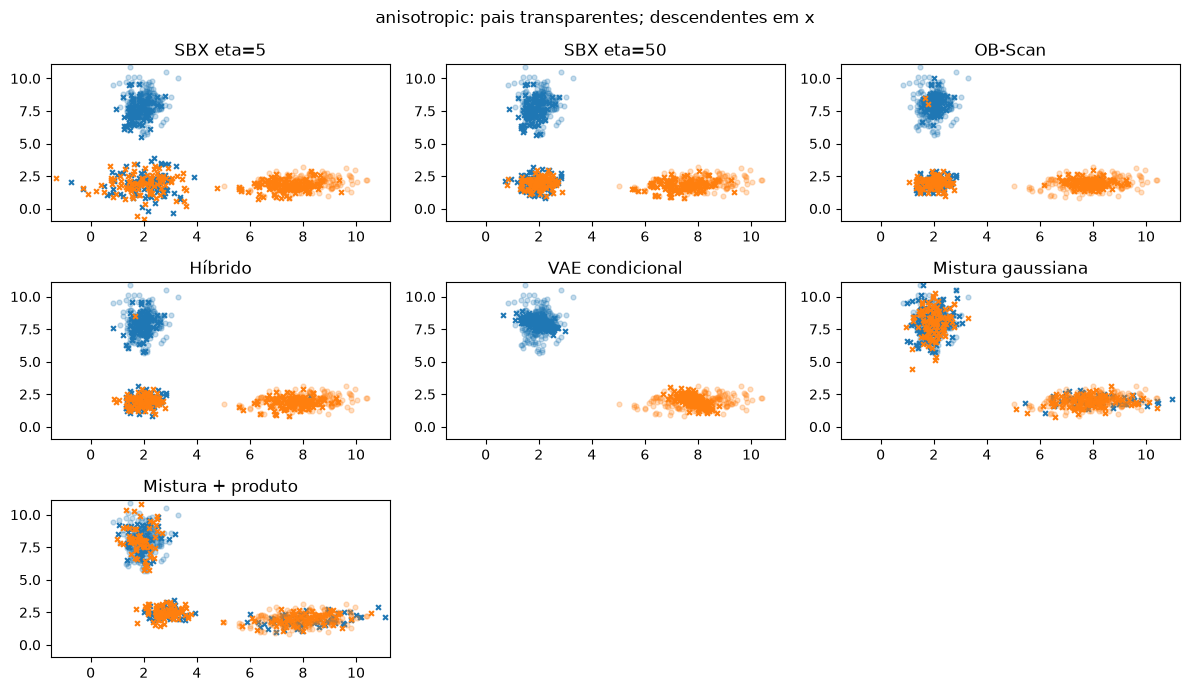

Políticas de seleção:   0%|          | 0/3 [00:00<?, ?it/s]

,policy,generation,fitness_mean,task_0,task_1
0,global,1,0.885773,208,192
1,global,2,0.905288,212,188
2,global,3,0.915192,209,191
3,global,4,0.922743,188,212
4,global,5,0.929437,156,244
5,global,6,0.934272,129,271
6,global,7,0.938265,126,274
7,global,8,0.941166,131,269
8,global,9,0.944335,126,274
9,global,10,0.947107,111,289


,trajectory,generation,policy,survivors,offspring_survivors,cross_task_survivors,task_0,task_1
0,global,1,global,400,145,3,208,192
1,global,1,task,400,146,3,200,200
2,global,1,task_niching,400,131,1,200,200
3,global,2,global,400,143,5,212,188
4,global,2,task,400,144,5,200,200
...,...,...,...,...,...,...,...,...
175,task_niching,19,task,400,107,0,200,200
176,task_niching,19,task_niching,400,86,0,200,200
177,task_niching,20,global,400,97,0,197,203
178,task_niching,20,task,400,98,0,200,200


In [8]:
if config.RUN_BENCHMARKS:
    benchmark_metrics, samples = run_benchmarks(size=settings["benchmark_size"],
                                               vae_epochs=settings["vae_epochs"])
    display(benchmark_metrics)
    figures = plot_benchmarks(samples)
    plt.show()
if config.RUN_SELECTION_STUDY:
    trajectories, decisions = selection_study(size=settings["benchmark_size"],
                                              generations=settings["benchmark_generations"])
    display(trajectories)
    display(decisions)

## 6. Cross-fitting e limites da interpretação

Cinco folds externos reservam 30 reais por vez. Scaler, calibração, nichos e modelos gerativos usam somente os 120 reais de treinamento. Cada execução gera 30 sintéticos (10 por espécie). Um Random Forest com CV interna de três folds discrimina esses sintéticos dos 30 reais reservados.

A comparação usa o mesmo orçamento de gerações e as mesmas seeds, mas os métodos não têm o mesmo custo por geração: são registrados tempo e avaliações de fitness. Os epochs e a capacidade do VAE precisam de análise de sensibilidade antes de conclusões sobre superioridade. O perfil rápido não garante convergência do VAE.

Os cinco nichos permanecem fixos e o híbrido permanece probabilístico, conforme as decisões desta iteração.

**Leitura do perfil rápido salvo:** o VAE teve apenas sete candidatos sobreviventes na última geração. A população avaliada também preserva indivíduos da inicialização e de gerações anteriores; seus escores discriminativos não devem ser atribuídos isoladamente ao decoder. Observe conjuntamente a perda, a diversidade e a sobrevivência dos candidatos.

In [9]:
if config.RUN_CROSSFIT:
    crossfit = crossfit_suite(x_real, species, conditions, settings)
    display(crossfit.groupby("condition")[["accuracy", "roc_auc"]].agg(["mean", "std"]))
print(f"Execução concluída: perfil {settings['profile']}; {len(runs)} condições.")

Crossfit: fold e condição:   0%|          | 0/30 [00:00<?, ?it/s]

accuracy             roc_auc          
                      mean       std      mean       std
condition                                               
Híbrido 50/50     0.740000  0.067289  0.845333  0.059981
OB-Scan           0.756667  0.077817  0.810333  0.086365
SBX               0.730000  0.046248  0.854000  0.038398
gaussian_mixture  0.726667  0.043461  0.796000  0.073500
gaussian_product  0.683333  0.037268  0.777333  0.054691
vae_eda           0.690000  0.036515  0.776333  0.087974

Execução concluída: perfil full; 6 condições.
